# Neural rendering of the Phong model

A conditional GAN gets the scene parameters and draws the image of the sphere. The renderer of the task gives the
reference images. The Kaggle jobs are in `WORKLOG.md`.

In [1]:
import warnings

import pandas as pd
from IPython.display import Image, display

from metrics import METRICS, load_summaries, metric_correlation, plot_histories, scores_by_size, sphere_diameter
from training import plot_render_pairs, plot_scenes

warnings.filterwarnings("ignore")
RESULTS = "results"
params = pd.read_csv(f"{RESULTS}/data-v1/params.csv")

## Data

3000 images of 128 x 128 px: 2400 train and 600 test. The camera does not move. Each scene has a random position of
the sphere and of the light, a random color and shininess.

Top row: the full images. The sphere is far from the camera in most scenes, so it is small. Bottom row: a zoom of the
area in the dashed square.

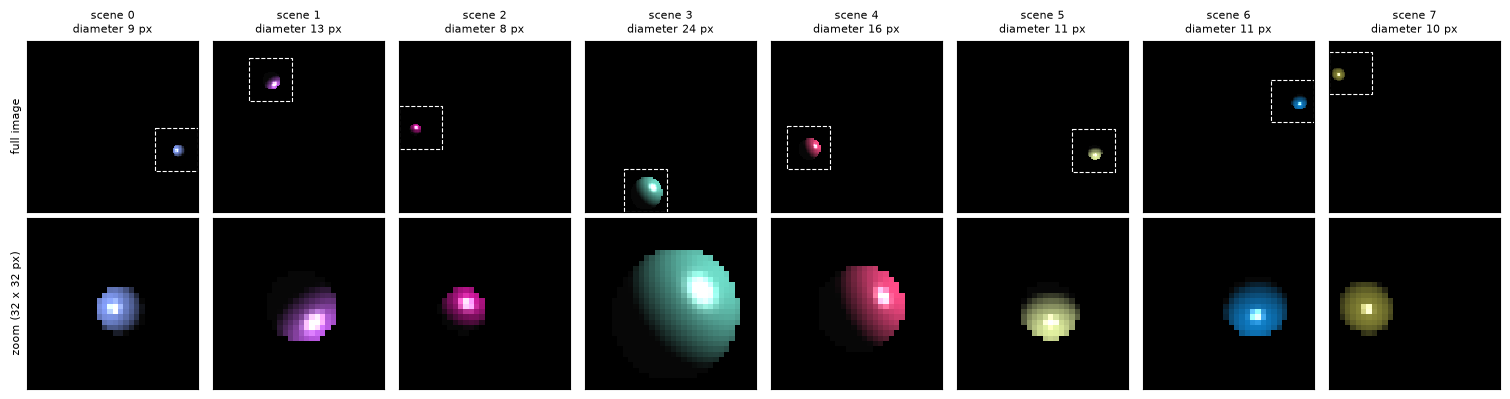

In [2]:
plot_scenes(f"{RESULTS}/data-v1/preview.png", params);

In [3]:
pd.Series(sphere_diameter(params), name="sphere diameter (px)").describe().round(1).to_frame().T

,count,mean,std,min,25%,50%,75%,max
sphere diameter (px),3000.0,11.3,4.6,6.8,8.7,10.0,12.2,76.8


## Main result

`gan-v2a` in the renderer, mean over the 600 test scenes (job `render-v1`).

In [4]:
render = pd.read_json(f"{RESULTS}/render-v1/summary.json", typ="series")
pd.DataFrame([render[METRICS]], index=["neural_renderer"]).astype(float).round(5)

,FLIP,LPIPS,SSIM,Hausdorff
neural_renderer,0.00074,0.00099,0.9995,1.50079


## Experiments

Each variant changes one thing in `gan-v1a`. The scores use the float output of the network on the 600 test images.

| Codename | Change |
|---|---|
| `gan-v1a` | main model: GAN + L1, 11 features, relative coordinates, mirror augmentation, 40000 steps |
| `gan-v1b` | only L1 |
| `gan-v1c` | raw parameters, no relative coordinates |
| `gan-v1d` | no relative coordinates |
| `gan-v1e` | GAN weight 1 instead of 5 |
| `gan-v1f` | seed 1 |
| `gan-v2a` | 100000 steps |
| `gan-v2b` | no mirror augmentation |
| `gan-v3a` | only L1, 100000 steps |
| `gan-v3b` | 100000 steps, seed 1 |

In [5]:
RUNS = ["gan-v1a", "gan-v1b", "gan-v1c", "gan-v1d", "gan-v1e", "gan-v1f", "gan-v2a", "gan-v2b", "gan-v3a", "gan-v3b"]
summaries = load_summaries(RESULTS, RUNS)
summaries[[*METRICS, "best_step", "train_minutes"]].round(5)

,FLIP,LPIPS,SSIM,Hausdorff,best_step,train_minutes
codename,,,,,,
gan-v1a,0.00156,0.00117,0.99927,1.60184,30000,71.7
gan-v1b,0.00131,0.00197,0.99940,2.09254,40000,47.1
gan-v1c,0.00255,0.00393,0.99772,2.37898,40000,68.4
gan-v1d,0.00186,0.00143,0.99905,1.65113,32000,67.3
gan-v1e,0.00136,0.00134,0.99934,1.57506,40000,71.8
gan-v1f,0.00131,0.00103,0.99936,1.49797,40000,71.1
gan-v2a,0.00115,0.00099,0.99949,1.50079,80000,167.8
gan-v2b,0.00204,0.00234,0.99881,2.31603,22000,68.5
gan-v3a,0.00118,0.00156,0.99944,1.80360,100000,116.2


## Learning curves

Metrics on the 200 tune images, log scale. The long runs have a peak near step 15000, when the learning rate is still
high, and then recover.

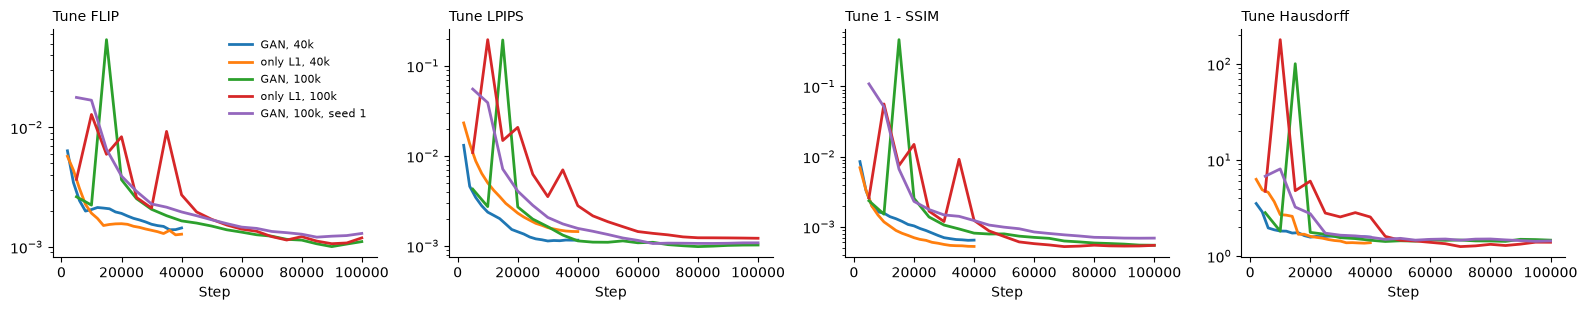

In [6]:
plot_histories(RESULTS, {"gan-v1a": "GAN, 40k", "gan-v1b": "only L1, 40k", "gan-v2a": "GAN, 100k",
                         "gan-v3a": "only L1, 100k", "gan-v3b": "GAN, 100k, seed 1"});

Raw parameters need about 15000 steps before the network finds the sphere. Without the mirror augmentation, LPIPS
increases after step 20000 (overfitting).

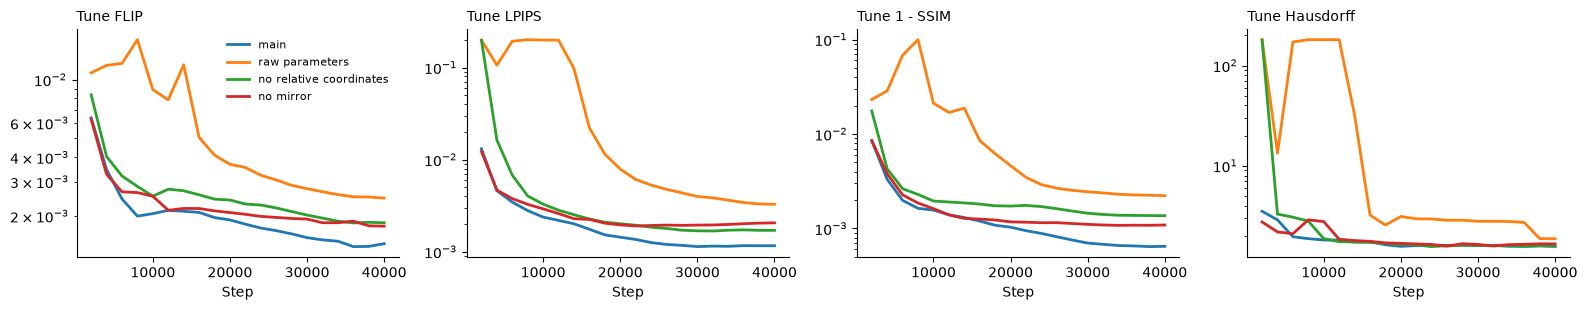

In [7]:
plot_histories(RESULTS, {"gan-v1a": "main", "gan-v1c": "raw parameters", "gan-v1d": "no relative coordinates",
                         "gan-v2b": "no mirror"});

## Test images of the final model

Each row is one test scene. Columns 1-2: the full Phong image and the network image, the dashed square is the zoom
area. Columns 3-4: the zoom. Column 5: the FLIP error of each pixel (black = no error, yellow = large error).

The two best and two middle scenes have no visible difference. The two worst scenes have the light behind the sphere,
so only a thin bright edge is visible. The network draws this edge, but a little too smooth.

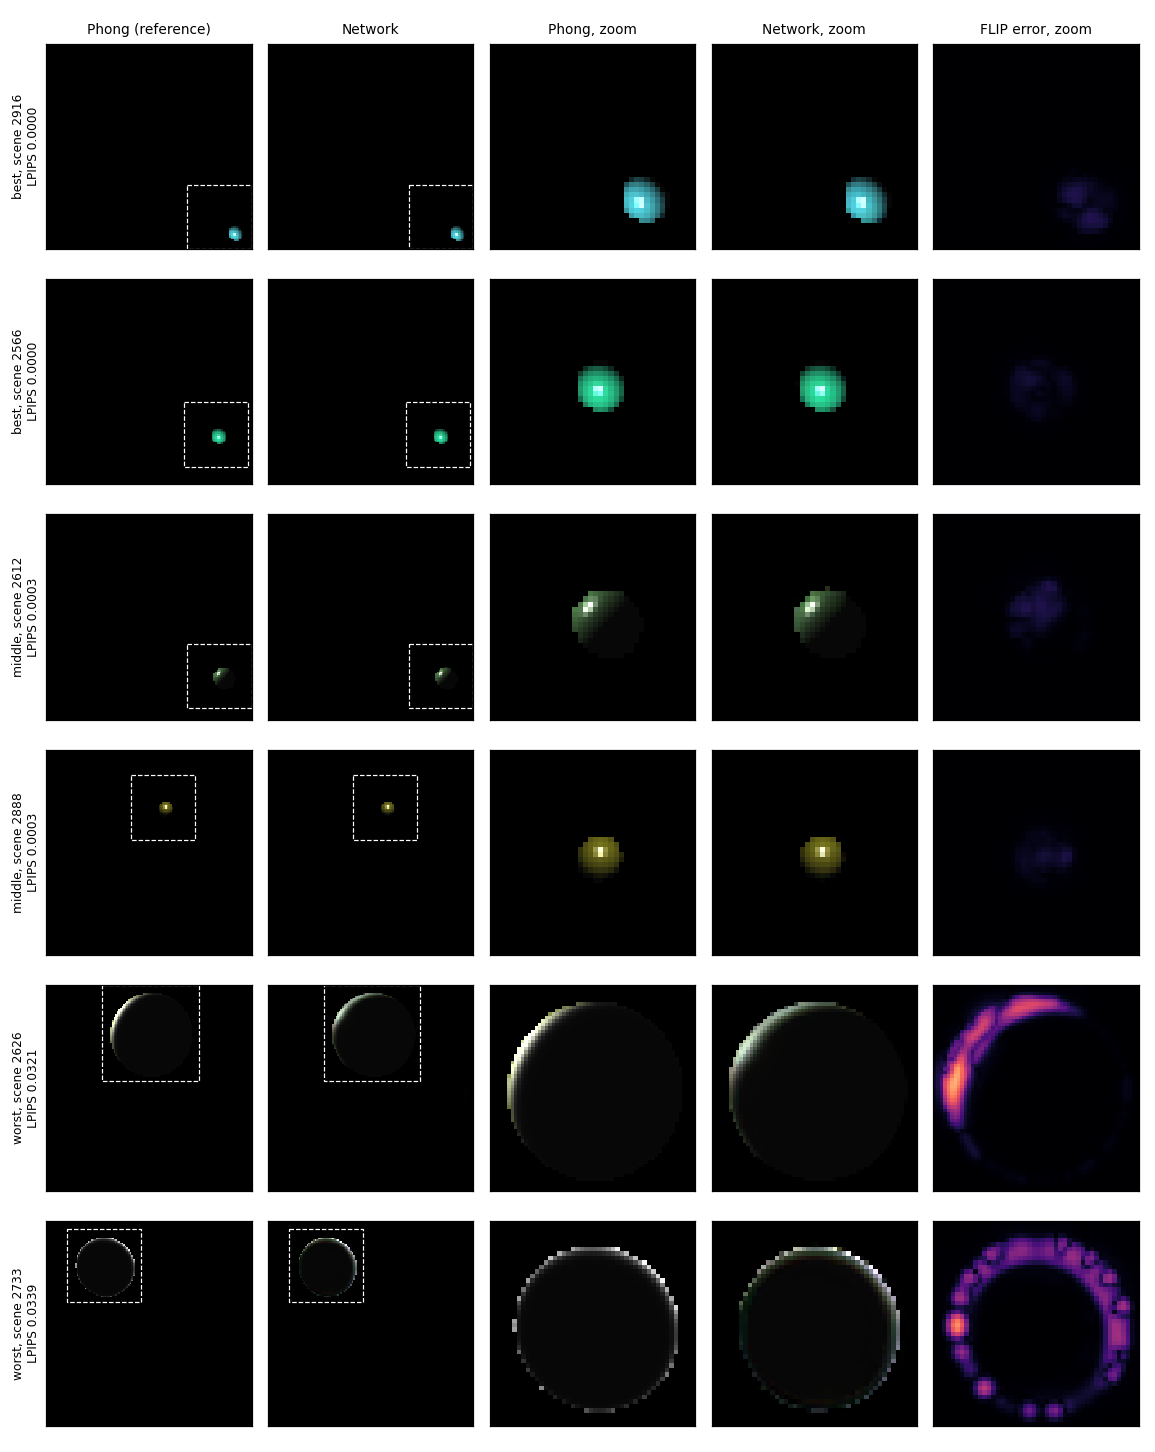

In [8]:
display(Image(f"{RESULTS}/figures-v2/examples-gan-v2a.png"))

## The network in the renderer

`renderer/src/neural_window.py` draws the Phong image and the network image side by side for each scene. Start it with
`python renderer/src/main.py --generator <path to generator.pt>`.

The figure shows the first 4 test scenes from the renderer. The last column is the absolute difference, 10 times
brighter, because without this it is black.

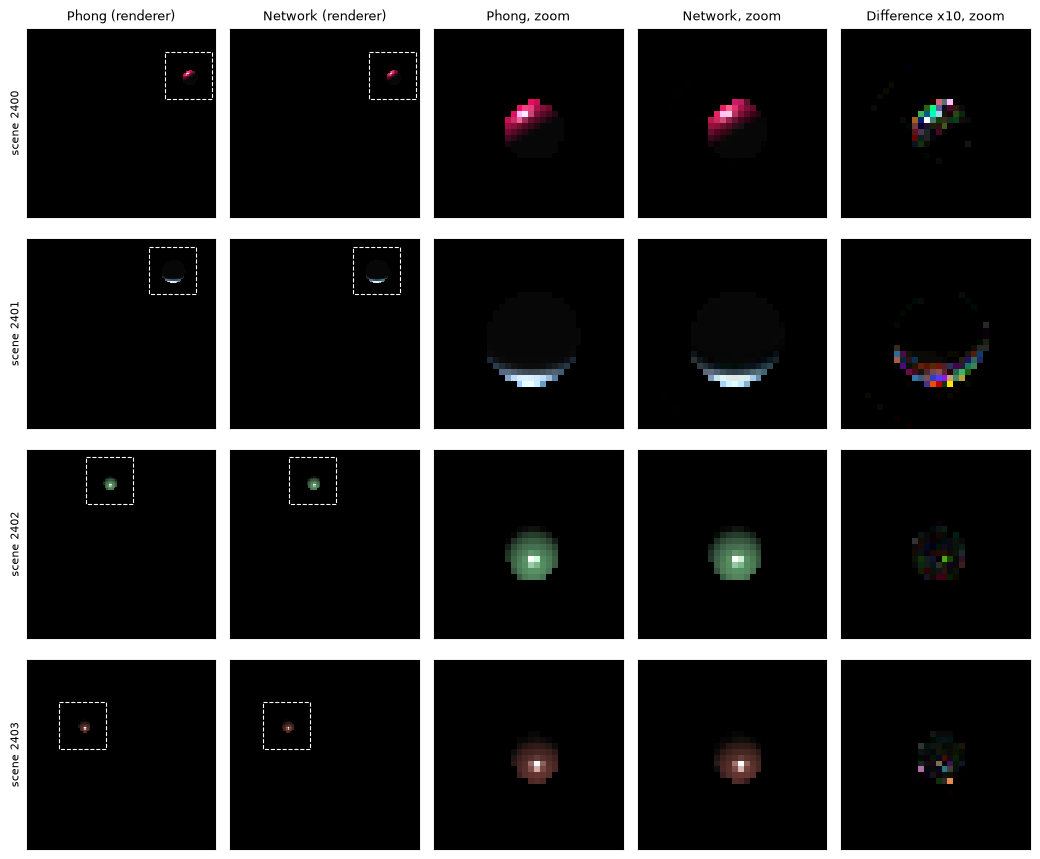

In [9]:
plot_render_pairs(f"{RESULTS}/render-v1/preview.png");

The Phong images of the renderer are equal to the data set (3000 of 3000). The network image differs from the training
predictions by at most 1/255. One image takes 54 ms on the CPU.

In [10]:
render[["phong_equal_to_data_set", "max_difference_to_training_predictions", "ms_per_image_cpu"]]

phong_equal_to_data_set                   3000
max_difference_to_training_predictions     1.0
ms_per_image_cpu                          53.9
dtype: object

# Do all metrics show the quality well?

## Change test

Simple changes of the 600 reference images, scored against the reference.

In [11]:
pd.read_csv(f"{RESULTS}/render-v1/change-test.csv", index_col=0).round(4)

,FLIP,LPIPS,SSIM,Hausdorff
same image,0.0000,0.0000,1.0000,0.0000
shift 2 px,0.0052,0.0164,0.9897,2.5756
shift 10 px,0.0115,0.0811,0.9747,14.2769
swap R and B,0.0027,0.0212,0.9974,0.9749
50% darker,0.0055,0.0299,0.9949,1.4424
black image,0.0067,0.1959,0.9842,181.0193


A black image gets a better FLIP than a shift of 10 px, and SSIM 0.98. FLIP and SSIM average over all pixels, and most
pixels are background. Only LPIPS gives the black image the worst score. The Hausdorff distance is not defined for an
image without edges, so the code uses the image diagonal (181 px).

## Full image and crop

The same network images, scored on the full image and on a 64 x 64 crop around the sphere.

In [12]:
full = pd.read_csv(f"{RESULTS}/render-v1/scores.csv")
crop = pd.read_csv(f"{RESULTS}/render-v1/scores-crop.csv")
pd.DataFrame({"full image": full[METRICS].mean(), "crop 64x64": crop[METRICS].mean()}).T.round(5)

,FLIP,LPIPS,SSIM,Hausdorff
full image,0.00074,0.00099,0.99950,1.50079
crop 64x64,0.00295,0.00191,0.99782,1.50079


The error of the network is the same, but FLIP is 4 times larger on the crop and LPIPS 2 times larger. The value
depends on how much background the image has.

## Float output and 8-bit image

The training scores the float output. The renderer saves 8-bit PNG images.

In [13]:
training = pd.read_csv(f"{RESULTS}/gan-v2a/scores.csv")
table = pd.DataFrame({"float output": training[METRICS].mean(), "8-bit image": full[METRICS].mean()}).T
table.loc["share of images better in 8-bit"] = (full[METRICS] < training[METRICS]).mean()
table.round(5)

,FLIP,LPIPS,SSIM,Hausdorff
float output,0.00115,0.00099,0.99949,1.50079
8-bit image,0.00074,0.00099,0.99950,1.50079
share of images better in 8-bit,1.00000,0.51167,0.01167,0.00000


Only FLIP changes, and it is better for all 600 images. The rounding sets very small background values to 0. These
values are not visible, but FLIP adds them over the full background.

## Sphere size

In [14]:
scores_by_size(full, params).round(5)

,images,FLIP,LPIPS,SSIM,Hausdorff
diameter (px),,,,,
"[6, 8)",57,0.00038,0.00025,0.99988,1.06529
"[8, 10)",249,0.00045,0.00048,0.99983,1.15364
"[10, 13)",171,0.00060,0.00078,0.99967,1.44915
"[13, 20)",100,0.00103,0.00154,0.99921,2.03436
"[20, 128)",23,0.00451,0.00751,0.99500,4.40260


All errors increase with the sphere size, because a large sphere has more pixels that can be wrong. The mean score
thus also depends on the sphere sizes in the test set.

## Agreement of the metrics

Spearman correlation over the 600 test images. SSIM is a similarity, so agreement with SSIM is a negative value.

In [15]:
metric_correlation(full).round(2)

,FLIP,LPIPS,SSIM,Hausdorff
FLIP,1.00,0.54,-0.61,0.32
LPIPS,0.54,1.00,-0.82,0.40
SSIM,-0.61,-0.82,1.00,-0.41
Hausdorff,0.32,0.40,-0.41,1.00


LPIPS and SSIM agree best (-0.82). The Hausdorff distance agrees least (0.3-0.4), because it sees only the edges.

## GAN against only L1, and two seeds

In [16]:
pairs = {"GAN, 40k": "gan-v1a", "GAN, 40k, seed 1": "gan-v1f", "only L1, 40k": "gan-v1b",
         "GAN, 100k": "gan-v2a", "GAN, 100k, seed 1": "gan-v3b", "only L1, 100k": "gan-v3a"}
summaries.loc[list(pairs.values()), METRICS].set_axis(list(pairs), axis=0).round(5)

,FLIP,LPIPS,SSIM,Hausdorff
"GAN, 40k",0.00156,0.00117,0.99927,1.60184
"GAN, 40k, seed 1",0.00131,0.00103,0.99936,1.49797
"only L1, 40k",0.00131,0.00197,0.99940,2.09254
"GAN, 100k",0.00115,0.00099,0.99949,1.50079
"GAN, 100k, seed 1",0.00142,0.00109,0.99930,1.58711
"only L1, 100k",0.00118,0.00156,0.99944,1.80360


In FLIP and SSIM, the difference between two seeds of the GAN is as large as the difference between the GAN and only
L1. These two metrics cannot tell which model is better. In LPIPS and the Hausdorff distance, the GAN is better with
both seeds.

## Answer

No. FLIP and SSIM mostly measure the background: a black image gets good scores, and the value changes with the crop
size and with an invisible rounding error. The Hausdorff distance sees only the edge position, not the color. LPIPS
works best here. A fair comparison needs more than one metric and a look at the worst images.